<a href="https://colab.research.google.com/github/emirbekk08/data-analysis-practice/blob/main/Practical_Work_7_Random_Forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

uploaded = files.upload()

Saving insurance.csv to insurance (2).csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("insurance.csv")

print("Размер датасета:", df.shape)
print("\nПервые 5 строк:")
display(df.head())

print("\nИнформация о данных:")
df.info()

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nСтатистика целевой переменной:")
print(df["charges"].describe())

Размер датасета: (1338, 7)

Первые 5 строк:


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Пропущенные значения:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Статистика целевой переменной:
count     1338.000000
mean     13270.422265
std      12110.011237
min       1121.873900
25%       4740.287150
50%       9382.033000
75%      16639.912515
max      63770.428010
Name: charges, dtype: float64


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Удаляем строки с пропущенными значениями, если они есть
df = df.dropna().copy()

# Признаки и целевая переменная
X = df.drop(columns=["charges"])
y = df["charges"]

# Числовые и категориальные признаки
numeric_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Кодируем текстовые категории числами через One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Делим данные на обучающую и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

Обучающая выборка: (1070, 6)
Тестовая выборка: (268, 6)


In [5]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

models = {
    "Decision Tree": DecisionTreeRegressor(random_state=42),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).round(3)
display(results_df)

,Model,MAE,RMSE,R2
0,Decision Tree,2944.361,6162.921,0.755
1,Random Forest,2548.535,4588.228,0.864


In [6]:
from sklearn.model_selection import GridSearchCV, KFold

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 5]
}

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:")
print(grid_search.best_params_)

print("\nЛучший CV RMSE:")
print(round(-grid_search.best_score_, 3))

best_model = grid_search.best_estimator_

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Лучшие параметры:
{'model__max_depth': 10, 'model__min_samples_leaf': 5, 'model__n_estimators': 100}

Лучший CV RMSE:
4617.801


In [7]:
tuned_predictions = best_model.predict(X_test)

comparison = pd.DataFrame([
    {
        "Model": "Random Forest (default)",
        "MAE": results_df.loc[
            results_df["Model"] == "Random Forest", "MAE"
        ].iloc[0],
        "RMSE": results_df.loc[
            results_df["Model"] == "Random Forest", "RMSE"
        ].iloc[0],
        "R2": results_df.loc[
            results_df["Model"] == "Random Forest", "R2"
        ].iloc[0]
    },
    {
        "Model": "Random Forest (tuned)",
        "MAE": mean_absolute_error(y_test, tuned_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, tuned_predictions)),
        "R2": r2_score(y_test, tuned_predictions)
    }
]).round(3)

display(comparison)

,Model,MAE,RMSE,R2
0,Random Forest (default),2548.535,4588.228,0.864
1,Random Forest (tuned),2451.957,4359.991,0.878


,Feature,Importance
5,cat__smoker_no,0.4919
1,num__bmi,0.1916
6,cat__smoker_yes,0.1713
0,num__age,0.1253
2,num__children,0.0107
7,cat__region_northeast,0.0026
9,cat__region_southeast,0.0015
3,cat__sex_female,0.0015
4,cat__sex_male,0.0013
10,cat__region_southwest,0.0012


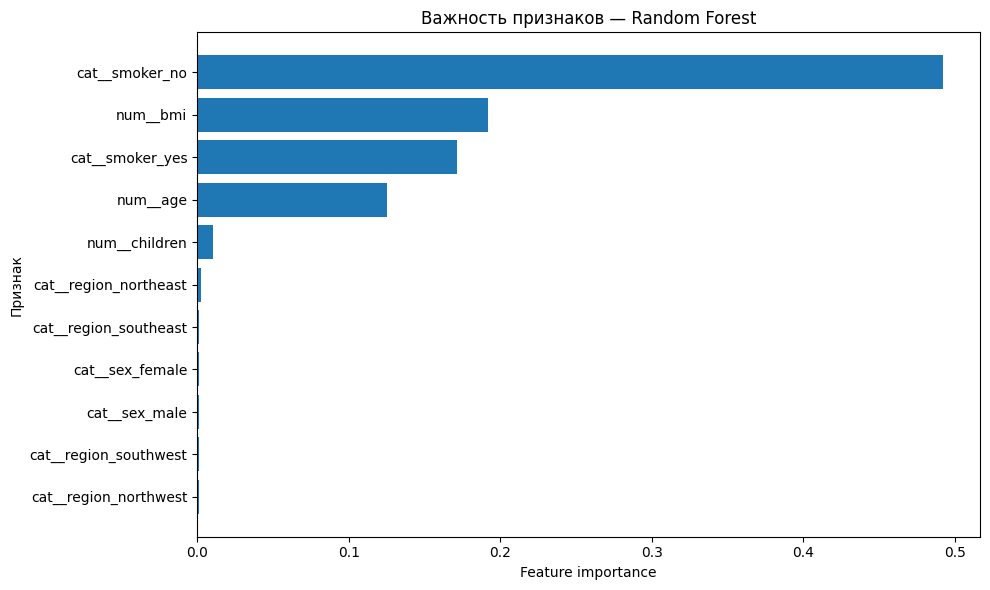

Два наиболее важных признака:
          Feature  Importance
5  cat__smoker_no    0.491893
1        num__bmi    0.191579


In [8]:
# Получаем обученную модель и преобразованные имена признаков
preprocessor_fitted = best_model.named_steps["preprocessor"]
rf_fitted = best_model.named_steps["model"]

feature_names = preprocessor_fitted.get_feature_names_out()
importances = rf_fitted.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.round(4))

plt.figure(figsize=(10, 6))
plt.barh(
    importance_df["Feature"][::-1],
    importance_df["Importance"][::-1]
)
plt.xlabel("Feature importance")
plt.ylabel("Признак")
plt.title("Важность признаков — Random Forest")
plt.tight_layout()
plt.show()

print("Два наиболее важных признака:")
print(importance_df.head(2))

In [9]:
# Порядок удаления: от наименее важного к наиболее важному
ordered_features = importance_df["Feature"].tolist()

feature_groups = [
    numeric_features,
    categorical_features
]

def make_pipeline(selected_features):
    selected_num = [
        f for f in numeric_features if f in selected_features
    ]
    selected_cat = [
        f for f in categorical_features if f in selected_features
    ]

    transformers = []

    if selected_num:
        transformers.append(("num", "passthrough", selected_num))

    if selected_cat:
        transformers.append((
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            selected_cat
        ))

    return Pipeline([
        ("preprocessor", ColumnTransformer(
            transformers=transformers,
            remainder="drop"
        )),
        ("model", RandomForestRegressor(
            **{
                key.replace("model__", ""): value
                for key, value in grid_search.best_params_.items()
            },
            random_state=42,
            n_jobs=-1
        ))
    ])

# Начинаем со всех исходных признаков
selected = numeric_features + categorical_features
feature_experiment = []

for feature in ordered_features:
    # Проверяем удаление исходного признака, а не отдельной категории
    original_feature = feature.split("__")[-1]

    if original_feature.startswith("num__"):
        original_feature = original_feature.replace("num__", "")

    # Определяем исходный столбец для закодированных признаков
    if original_feature.startswith("cat__"):
        original_feature = original_feature.replace("cat__", "")

    if original_feature in categorical_features:
        original_feature = original_feature.split("_")[0]

    if original_feature not in selected:
        continue

    if len(selected) <= 1:
        break

    candidate = [f for f in selected if f != original_feature]

    # Проверяем удаление одного исходного признака
    model = make_pipeline(candidate)
    model.fit(X_train[candidate], y_train)
    pred = model.predict(X_test[candidate])

    feature_experiment.append({
        "Removed feature": original_feature,
        "Remaining features": len(candidate),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "R2": r2_score(y_test, pred)
    })

    selected = candidate

display(pd.DataFrame(feature_experiment).round(3))

,Removed feature,Remaining features,RMSE,R2
0,bmi,5,6345.010,0.741
1,age,4,7405.196,0.647
2,children,3,7400.315,0.647


## Вывод по практической работе № 7 «Случайный лес»

В ходе практической работы был изучен алгоритм случайного леса для решения задачи регрессии. В качестве данных использован Medical Cost Personal Dataset с Kaggle, содержащий информацию о возрасте, ИМТ, курении, количестве детей, регионе проживания и стоимости медицинского страхования.

Были обучены и сравнены модели Decision Tree Regressor и Random Forest Regressor. Качество оценивалось с помощью MAE, RMSE и R². Затем с использованием пятиблочной кросс-валидации были подобраны гиперпараметры случайного леса: количество деревьев, максимальная глубина и минимальное количество объектов в листе.

Также была исследована важность признаков и проведён эксперимент по удалению наименее значимых признаков. По результатам эксперимента будет определено, какие признаки можно исключить без существенного ухудшения качества модели.

Случайный лес объединяет предсказания множества деревьев и может обеспечивать более устойчивые результаты, чем одиночное дерево. Фактическое преимущество моделей и влияние удаления признаков определяются полученными метриками на тестовой выборке.

In [11]:
from sklearn.base import clone

all_features = numeric_features + categorical_features

# Используем лучшие параметры, найденные ранее
best_params = {
    key.replace("model__", ""): value
    for key, value in grid_search.best_params_.items()
}

def evaluate_features(features):
    model = Pipeline([
        ("preprocessor", ColumnTransformer([
            ("num", "passthrough",
             [f for f in numeric_features if f in features]),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             [f for f in categorical_features if f in features])
        ], remainder="drop")),
        ("model", RandomForestRegressor(
            **best_params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train[features], y_train)
    pred = model.predict(X_test[features])

    return {
        "Features": ", ".join(features),
        "Number of features": len(features),
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    }

experiments = []

# Базовая модель со всеми признаками
experiments.append({
    "Removed feature": "None (baseline)",
    **evaluate_features(all_features)
})

# Удаляем каждый исходный признак по отдельности
for feature in all_features:
    remaining = [f for f in all_features if f != feature]

    experiments.append({
        "Removed feature": feature,
        **evaluate_features(remaining)
    })

experiment_df = pd.DataFrame(experiments)

display(
    experiment_df[
        ["Removed feature", "Number of features", "RMSE", "MAE", "R2"]
    ].round(3)
)

,Removed feature,Number of features,RMSE,MAE,R2
0,None (baseline),6,4359.991,2451.957,0.878
1,age,5,5934.725,4565.616,0.773
2,bmi,5,6345.010,3926.342,0.741
3,children,5,4538.787,2582.541,0.867
4,sex,5,4338.838,2434.487,0.879
5,smoker,5,11766.333,9301.811,0.108
6,region,5,4435.663,2486.063,0.873


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

all_features = numeric_features + categorical_features

best_params = {
    key.replace("model__", ""): value
    for key, value in grid_search.best_params_.items()
}

def evaluate_features(features):
    transformers = []

    nums = [f for f in numeric_features if f in features]
    cats = [f for f in categorical_features if f in features]

    if nums:
        transformers.append(("num", "passthrough", nums))

    if cats:
        transformers.append((
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            cats
        ))

    model = Pipeline([
        ("preprocessor", ColumnTransformer(transformers)),
        ("model", RandomForestRegressor(
            **best_params,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train[features], y_train)
    pred = model.predict(X_test[features])

    return {
        "Количество признаков": len(features),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    }

rows = []

# Базовая модель: все исходные признаки
rows.append({
    "Удалённый признак": "Нет (все признаки)",
    **evaluate_features(all_features)
})

# Удаляем каждый признак отдельно
for feature in all_features:
    remaining = [f for f in all_features if f != feature]

    rows.append({
        "Удалённый признак": feature,
        **evaluate_features(remaining)
    })

experiment_df = pd.DataFrame(rows)

display(experiment_df.round(3))

,Удалённый признак,Количество признаков,RMSE,MAE,R2
0,Нет (все признаки),6,4359.991,2451.957,0.878
1,age,5,5934.725,4565.616,0.773
2,bmi,5,6345.010,3926.342,0.741
3,children,5,4538.787,2582.541,0.867
4,sex,5,4338.838,2434.487,0.879
5,smoker,5,11766.333,9301.811,0.108
6,region,5,4435.663,2486.063,0.873


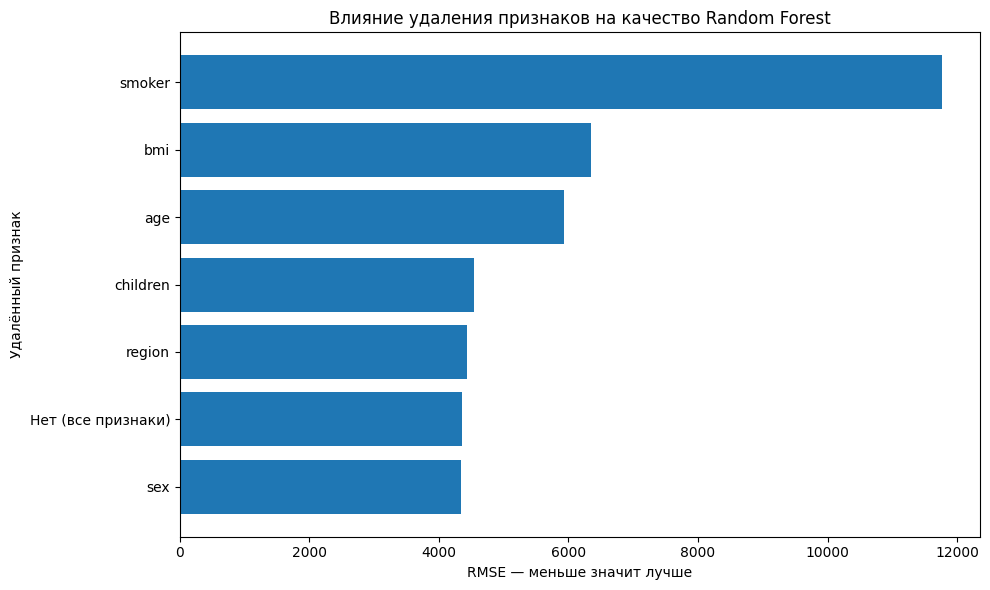

In [13]:
import matplotlib.pyplot as plt

plot_df = experiment_df.sort_values("RMSE")

plt.figure(figsize=(10, 6))
plt.barh(
    plot_df["Удалённый признак"],
    plot_df["RMSE"]
)

plt.xlabel("RMSE — меньше значит лучше")
plt.ylabel("Удалённый признак")
plt.title("Влияние удаления признаков на качество Random Forest")
plt.tight_layout()
plt.show()

## Вывод по практической работе № 7 «Случайный лес»

В ходе практической работы был изучен алгоритм Random Forest для решения задачи регрессии на датасете Medical Cost Personal Dataset с Kaggle.

Были обучены и сравнены модели Decision Tree Regressor и Random Forest Regressor. Для оценки качества использовались метрики MAE, RMSE и R². Также был выполнен подбор гиперпараметров случайного леса с помощью пятиблочной кросс-валидации по параметрам `n_estimators`, `max_depth` и `min_samples_leaf`.

Для модели со всеми шестью исходными признаками получены следующие результаты: RMSE = 4359.991, MAE = 2451.957, R² = 0.878.

В эксперименте по удалению признаков установлено, что наибольшее ухудшение качества наблюдается при удалении `smoker`: R² снижается до 0.108. Удаление `age` и `bmi` также заметно ухудшает результаты. При удалении `sex` качество практически не меняется: R² составляет 0.879, а RMSE немного уменьшается. Удаление `children` и `region` приводит к небольшому ухудшению качества.

Таким образом, `smoker`, `age` и `bmi` являются важными признаками для прогнозирования стоимости страхования. Признак `sex` можно рассматривать как кандидата на исключение, поскольку его удаление не ухудшило качество на данной тестовой выборке. Окончательное решение об исключении признаков желательно подтвердить дополнительной кросс-валидацией.

В результате работы были освоены обучение случайного леса, настройка гиперпараметров, анализ важности признаков и экспериментальная оценка влияния признаков на качество регрессионной модели.